**Importação de bibliotecas**

In [ ]:
!pip install numpy pandas matplotlib scikit-learn

**Instalando o pacote ucimlrepo**

In [ ]:
!pip install ucimlrepo

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from ucimlrepo import fetch_ucirepo

import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

**Importando o database**

In [ ]:
energy_efficiency = fetch_ucirepo(id=242)
X = energy_efficiency.data.features
y = energy_efficiency.data.targets

dados = pd.concat([X, y], axis=1)
dados.columns = ["X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8", "Y1", "Y2"]

AZUL = "#1f77b4"
LARANJA = "#ff7f0e"
TEAL = "#008080"
TINTA = "#333333"
TINTA_2 = "#555555"

def finalizar(nome):
    plt.tight_layout()
    plt.show()

Distribuição de carga térmica de aquecimento

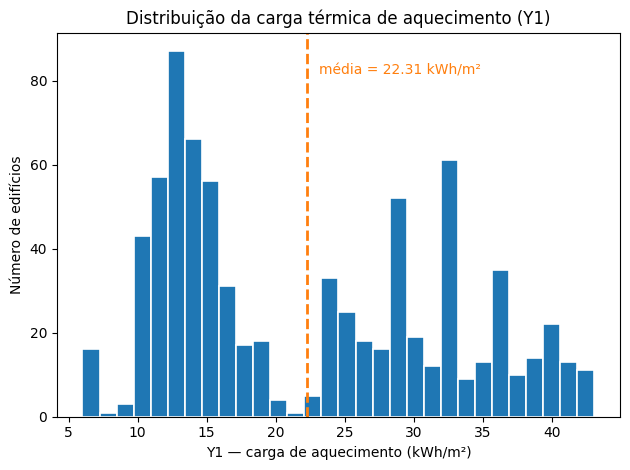

Y1: mínimo = 6.01 | média = 22.31 | máximo = 43.1 | desvio-padrão = 10.09 kWh/m²


In [ ]:
alvo = dados["Y1"]

plt.figure()
plt.hist(alvo, bins=30, color=AZUL, edgecolor="white", linewidth=1.2)
plt.axvline(alvo.mean(), color=LARANJA, linestyle="--", linewidth=2)
plt.annotate("média = " + str(round(alvo.mean(), 2)) + " kWh/m²",
             xy=(alvo.mean(), plt.ylim()[1] * 0.92),
             xytext=(8, 0), textcoords="offset points",
             color=LARANJA, fontsize=10, va="top")
plt.title("Distribuição da carga térmica de aquecimento (Y1)")
plt.xlabel("Y1 — carga de aquecimento (kWh/m²)")
plt.ylabel("Número de edifícios")
finalizar("01_distribuicao_y1")

print("Y1: mínimo = " + str(round(alvo.min(), 2)) +
      " | média = " + str(round(alvo.mean(), 2)) +
      " | máximo = " + str(round(alvo.max(), 2)) +
      " | desvio-padrão = " + str(round(alvo.std(), 2)) + " kWh/m²")

Correlação de Pearson

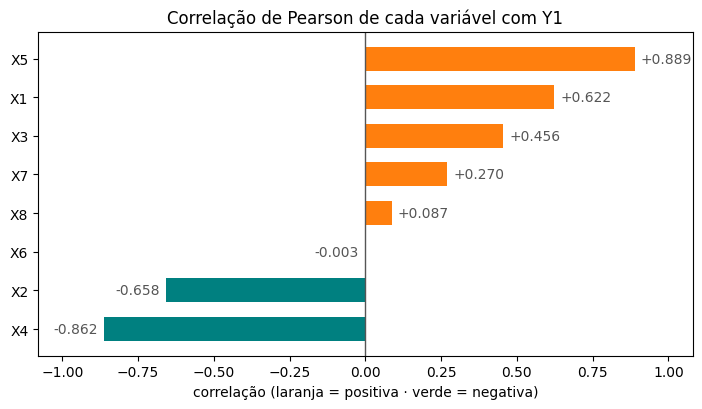

X5    0.8894
X4   -0.8618
X2   -0.6581
X1    0.6223
X3    0.4557
X7    0.2698
X8    0.0874
X6   -0.0026


In [ ]:
correlacoes = dados.corr(numeric_only=True)["Y1"].drop(["Y1", "Y2"]).sort_values()

plt.figure(figsize=(7.2, 4.2))
cores = [LARANJA if valor > 0 else TEAL for valor in correlacoes]
plt.barh(correlacoes.index, correlacoes.values, color=cores, height=0.62)
for nome, valor in correlacoes.items():
    deslocamento = 0.02 if valor > 0 else -0.02
    plt.text(valor + deslocamento, nome, format(valor, "+.3f"),
             va="center", ha="left" if valor > 0 else "right",
             fontsize=10, color=TINTA_2)
plt.axvline(0, color=TINTA_2, linewidth=1)
plt.xlim(-1.08, 1.08)
plt.title("Correlação de Pearson de cada variável com Y1")
plt.xlabel("correlação (laranja = positiva · verde = negativa)")
finalizar("02_correlacoes")

print(correlacoes.sort_values(key=abs, ascending=False).round(4).to_string())

Matriz de correlação

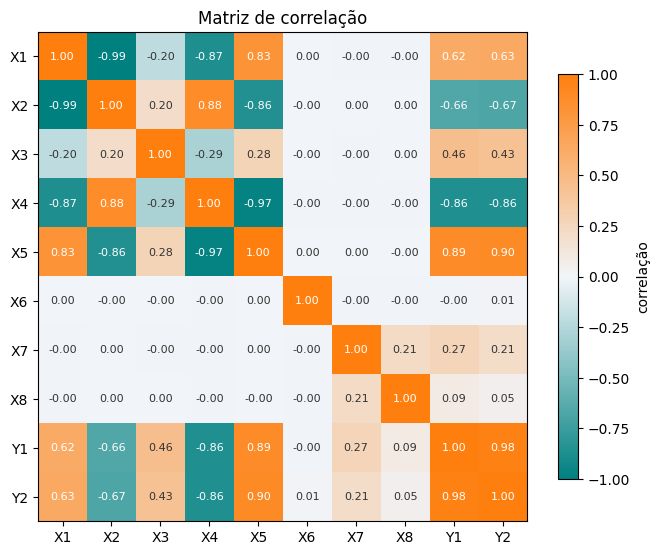

In [ ]:
mapa_divergente = LinearSegmentedColormap.from_list(
    "divergente", [TEAL, "#F1F5F9", LARANJA])

matriz = dados.corr(numeric_only=True)

plt.figure(figsize=(6.8, 5.6))
plt.imshow(matriz, cmap=mapa_divergente, vmin=-1, vmax=1)
plt.colorbar(label="correlação", shrink=0.82)
plt.xticks(range(len(matriz)), matriz.columns)
plt.yticks(range(len(matriz)), matriz.columns)
for i in range(len(matriz)):
    for j in range(len(matriz)):
        plt.text(j, i, format(matriz.iloc[i, j], ".2f"),
                 ha="center", va="center", fontsize=8,
                 color=TINTA if abs(matriz.iloc[i, j]) < 0.6 else "white")
plt.title("Matriz de correlação")
plt.grid(False)
finalizar("03_matriz_correlacao")

Variáveis escolhidas

In [ ]:
VARIAVEL_X = "X5"
VARIAVEL_Y = "Y1"

ROTULOS = {
    "X1": "X1 — compacidade relativa",
    "X2": "X2 — área de superfície (m²)",
    "X3": "X3 — área de parede (m²)",
    "X4": "X4 — área de telhado (m²)",
    "X5": "X5 — altura total (m)",
    "X6": "X6 — orientação (código)",
    "X7": "X7 — área de vidro (fração)",
    "X8": "X8 — distribuição do vidro (código)",
    "Y1": "Y1 — carga de aquecimento (kWh/m²)",
}

rotulo_x, rotulo_y = ROTULOS[VARIAVEL_X], ROTULOS[VARIAVEL_Y]

r_pearson = dados[VARIAVEL_X].corr(dados[VARIAVEL_Y])
print("X escolhido :", rotulo_x)
print("y           :", rotulo_y)
print("correlação r = " + format(r_pearson, "+.4f") + "   (r² = " +
      format(r_pearson ** 2, ".4f") + ")")

X escolhido : X5 — altura total (m)
y           : Y1 — carga de aquecimento (kWh/m²)
correlação r = +0.8894   (r² = 0.7911)


Dispersão das variáveis

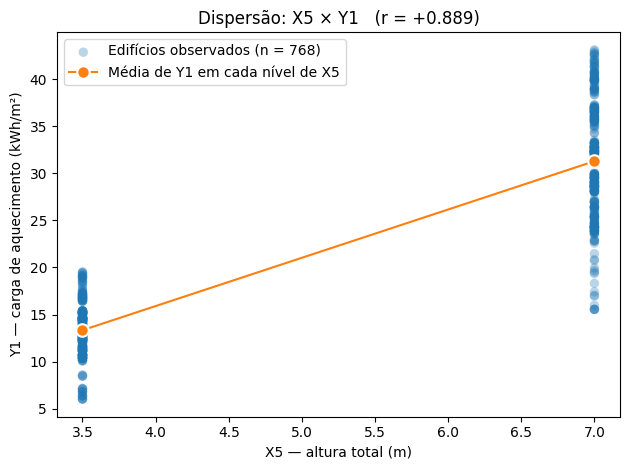

In [ ]:
plt.figure()
plt.scatter(dados[VARIAVEL_X], dados[VARIAVEL_Y],
            s=46, color=AZUL, alpha=0.30, edgecolors="none",
            label="Edifícios observados (n = " + str(len(dados)) + ")")

medias = dados.groupby(VARIAVEL_X)[VARIAVEL_Y].mean()
plt.plot(medias.index, medias.values, "o-", color=LARANJA, markersize=9,
         markeredgecolor="white", markeredgewidth=1.5,
         label="Média de Y1 em cada nível de " + VARIAVEL_X)
plt.title("Dispersão: " + VARIAVEL_X + " × " + VARIAVEL_Y +
          "   (r = " + format(r_pearson, "+.3f") + ")")
plt.xlabel(rotulo_x)
plt.ylabel(rotulo_y)
plt.legend(loc="upper left")
finalizar("06_dispersao")

Treinamento e testes

In [ ]:
X = dados[[VARIAVEL_X]]
y = dados[VARIAVEL_Y]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Total de observações :", len(dados))
print("Treino (80%)         :", len(X_treino))
print("Teste  (20%)         :", len(X_teste))
print()
print("Média de Y1 no treino:", round(y_treino.mean(), 3), "kWh/m²")
print("Média de Y1 no teste :", round(y_teste.mean(), 3), "kWh/m²")


Total de observações : 768
Treino (80%)         : 614
Teste  (20%)         : 154

Média de Y1 no treino: 22.155 kWh/m²
Média de Y1 no teste : 22.914 kWh/m²
As médias são parecidas -> o sorteio produziu conjuntos equilibrados.


Equação estimada da regressão linear

In [ ]:
modelo = LinearRegression()
modelo.fit(X_treino, y_treino)

a = modelo.intercept_
b = modelo.coef_[0]

print("=" * 62)
print("EQUAÇÃO ESTIMADA DA RETA")
print("=" * 62)
print("Y1 = " + format(a, ".4f") + " + " + format(b, ".4f") + " * " + VARIAVEL_X)
print()
print("Intercepto (a) = " + format(a, ".4f"))
print("Inclinação (b) = " + format(b, ".4f"))

EQUAÇÃO ESTIMADA DA RETA
Y1 = -4.5006 + 5.1050 * X5

Intercepto (a) = -4.5006
Inclinação (b) = 5.1050


Avaliação dos dados

In [ ]:
mae = mean_absolute_error(y_teste, y_previsto)
rmse = np.sqrt(mean_squared_error(y_teste, y_previsto))   # RMSE = raiz do MSE
r2 = r2_score(y_teste, y_previsto)

chute_media = np.full(len(y_teste), y_treino.mean())
mae_media = mean_absolute_error(y_teste, chute_media)
rmse_media = np.sqrt(mean_squared_error(y_teste, chute_media))

print("=" * 62)
print("DESEMPENHO NO CONJUNTO DE TESTE (" + str(len(y_teste)) + " edifícios)")
print("=" * 62)
print("MAE  = " + format(mae, ".4f") + " kWh/m²")
print("RMSE = " + format(rmse, ".4f") + " kWh/m²")
print("R²   = " + format(r2, ".4f") + "  (" + format(100 * r2, ".2f") +
      "% da variação de Y1 explicada)")
print()
print("Erro relativo (MAE  / média de Y1 no teste): " +
      format(100 * mae / y_teste.mean(), ".2f") + "%")
print("Erro relativo (RMSE / média de Y1 no teste): " +
      format(100 * rmse / y_teste.mean(), ".2f") + "%")
print()
print("-" * 62)
print("COMPARAÇÃO COM A MÉDIA")
print("-" * 62)
print("MAE  da média = " + format(mae_media, ".4f") +
      "   ->  o modelo reduz o erro em " +
      format(100 * (1 - mae / mae_media), ".1f") + "%")
print("RMSE da média = " + format(rmse_media, ".4f") +
      "   ->  o modelo reduz o erro em " +
      format(100 * (1 - rmse / rmse_media), ".1f") + "%")

DESEMPENHO NO CONJUNTO DE TESTE (154 edifícios)
MAE  = 3.6441 kWh/m²
RMSE = 4.6562 kWh/m²
R²   = 0.7920  (79.20% da variação de Y1 explicada)

Erro relativo (MAE  / média de Y1 no teste): 15.90%
Erro relativo (RMSE / média de Y1 no teste): 20.32%

--------------------------------------------------------------
COMPARAÇÃO COM A MÉDIA
--------------------------------------------------------------
MAE  da média = 9.2721   ->  o modelo reduz o erro em 60.7%
RMSE da média = 10.2375   ->  o modelo reduz o erro em 54.5%


Regressão linear simples

Valores reais e previstos

In [ ]:
y_previsto = modelo.predict(X_teste)

print("Primeiras 5 previsões:", np.round(y_previsto[:5], 3))
print("Valores reais        :", np.round(y_teste.values[:5], 3))

Primeiras 5 previsões: [13.367 13.367 31.234 31.234 13.367]
Valores reais        : [16.47 13.17 32.82 41.32 16.69]


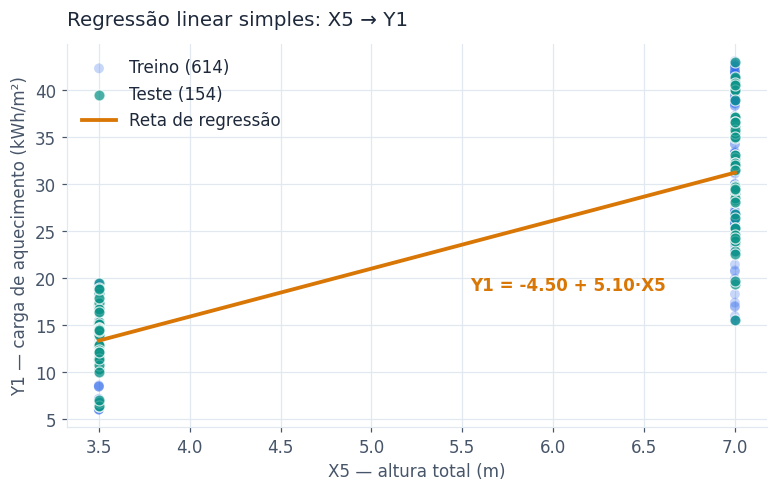

In [ ]:
grade_x = np.linspace(dados[VARIAVEL_X].min(), dados[VARIAVEL_X].max(), 100)
reta_y = modelo.predict(pd.DataFrame({VARIAVEL_X: grade_x}))

plt.figure()
plt.scatter(X_treino[VARIAVEL_X], y_treino, s=42, color=AZUL, alpha=0.25,
            edgecolors="none", label="Treino (" + str(len(X_treino)) + ")")
plt.scatter(X_teste[VARIAVEL_X], y_teste, s=52, color=TEAL, alpha=0.75,
            edgecolors="white", linewidths=0.8, label="Teste (" + str(len(X_teste)) + ")")
plt.plot(grade_x, reta_y, color=LARANJA, linewidth=2.5, label="Reta de regressão")
plt.annotate("Y1 = " + format(a, ".2f") + " + " + format(b, ".2f") + "·" + VARIAVEL_X,
             xy=(grade_x[55], reta_y[55]), xytext=(12, -28),
             textcoords="offset points", color=LARANJA, fontsize=11,
             fontweight="bold")
plt.title("Regressão linear simples: " + VARIAVEL_X + " → " + VARIAVEL_Y)
plt.xlabel(rotulo_x)
plt.ylabel(rotulo_y)
plt.legend(loc="upper left")
finalizar("07_reta_regressao")

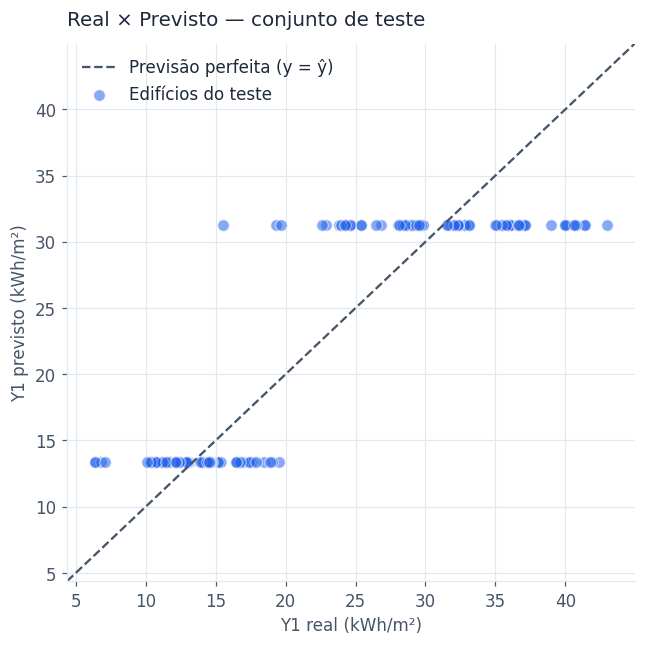

In [ ]:
limite_min = min(y_teste.min(), y_previsto.min()) - 2
limite_max = max(y_teste.max(), y_previsto.max()) + 2

plt.figure(figsize=(6.0, 6.0))
plt.plot([limite_min, limite_max], [limite_min, limite_max],
         color=TINTA_2, linestyle="--", linewidth=1.5,
         label="Previsão perfeita (y = ŷ)")
plt.scatter(y_teste, y_previsto, s=58, color=AZUL, alpha=0.55,
            edgecolors="white", linewidths=0.8, label="Edifícios do teste")
plt.xlim(limite_min, limite_max)
plt.ylim(limite_min, limite_max)
plt.title("Real × Previsto — conjunto de teste")
plt.xlabel("Y1 real (kWh/m²)")
plt.ylabel("Y1 previsto (kWh/m²)")
plt.legend(loc="upper left")
finalizar("08_real_vs_previsto")


Resíduos

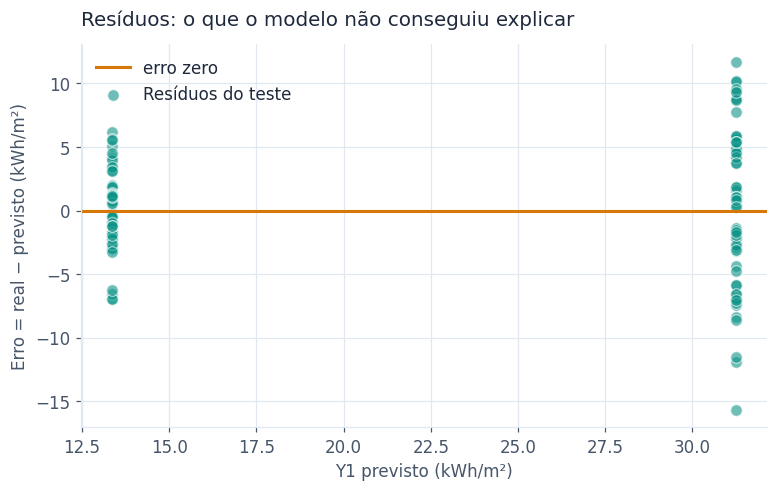

Média dos resíduos : 0.0333
Maior subestimação : 11.726 kWh/m² (o modelo previu MENOS do que o real)
Maior superestimação: -15.684 kWh/m² (o modelo previu MAIS do que o real)


In [ ]:
plt.figure()
plt.axhline(0, color=LARANJA, linewidth=2, label="erro zero")
plt.scatter(y_previsto, erros, s=58, color=TEAL, alpha=0.6,
            edgecolors="white", linewidths=0.8, label="Resíduos do teste")
plt.title("Resíduos: o que o modelo não conseguiu explicar")
plt.xlabel("Y1 previsto (kWh/m²)")
plt.ylabel("Erro = real − previsto (kWh/m²)")
plt.legend(loc="upper left")
finalizar("09_residuos")

print("Média dos resíduos : " + format(erros.mean(), ".4f"))
print("Maior subestimação : " + format(erros.max(), ".3f") +
      " kWh/m² (o modelo previu MENOS do que o real)")
print("Maior superestimação: " + format(erros.min(), ".3f") +
      " kWh/m² (o modelo previu MAIS do que o real)")

Maiores e Menores erros

In [ ]:
comparacao = pd.DataFrame({
    VARIAVEL_X: X_teste[VARIAVEL_X].to_numpy(),
    "Y1 real": y_teste.to_numpy(),
    "Y1 previsto": np.round(y_previsto, 3),
    "erro": np.round(erros, 3),
    "erro absoluto": np.round(np.abs(erros), 3),
})

print("=" * 72)
print("AMOSTRA DE 12 EDIFÍCIOS DO CONJUNTO DE TESTE")
print("=" * 72)
display(comparacao.sort_values(VARIAVEL_X).head(12).reset_index(drop=True))

print("\nOs 5 MAIORES erros (casos em que o modelo mais falhou):")
display(comparacao.reindex(comparacao["erro absoluto"]
                           .sort_values(ascending=False).index)
        .head(5).reset_index(drop=True))

print("\nOs 5 MENORES erros (acertos quase perfeitos):")
display(comparacao.reindex(comparacao["erro absoluto"]
                           .sort_values().index)
        .head(5).reset_index(drop=True))

AMOSTRA DE 12 EDIFÍCIOS DO CONJUNTO DE TESTE


,X5,Y1 real,Y1 previsto,erro,erro absoluto
0,3.5,16.47,13.367,3.103,3.103
1,3.5,13.17,13.367,-0.197,0.197
2,3.5,16.69,13.367,3.323,3.323
3,3.5,19.52,13.367,6.153,6.153
4,3.5,10.37,13.367,-2.997,2.997
5,3.5,17.69,13.367,4.323,4.323
6,3.5,18.46,13.367,5.093,5.093
7,3.5,12.30,13.367,-1.067,1.067
8,3.5,15.37,13.367,2.003,2.003
9,3.5,10.42,13.367,-2.947,2.947



Os 5 MAIORES erros (casos em que o modelo mais falhou):


,X5,Y1 real,Y1 previsto,erro,erro absoluto
0,7.0,15.55,31.234,-15.684,15.684
1,7.0,19.34,31.234,-11.894,11.894
2,7.0,42.96,31.234,11.726,11.726
3,7.0,19.68,31.234,-11.554,11.554
4,7.0,41.40,31.234,10.166,10.166



Os 5 MENORES erros (acertos quase perfeitos):


,X5,Y1 real,Y1 previsto,erro,erro absoluto
0,3.5,13.17,13.367,-0.197,0.197
1,7.0,31.53,31.234,0.296,0.296
2,3.5,13.02,13.367,-0.347,0.347
3,3.5,13.00,13.367,-0.367,0.367
4,3.5,13.00,13.367,-0.367,0.367


Dataset

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# fetch dataset
energy_efficiency = fetch_ucirepo(id=242)

# data (as pandas dataframes)
X = energy_efficiency.data.features
y = energy_efficiency.data.targets

# metadata
print(energy_efficiency.metadata)

# variable information
print(energy_efficiency.variables)

dados = pd.concat([X, y], axis=1)

print(dados.head())
print(dados.info())
print(dados.describe())
print(dados.tail())


{'uci_id': 242, 'name': 'Energy Efficiency', 'repository_url': 'https://archive.ics.uci.edu/dataset/242/energy+efficiency', 'data_url': 'https://archive.ics.uci.edu/static/public/242/data.csv', 'abstract': 'This study looked into assessing the heating load and cooling load requirements of buildings (that is, energy efficiency) as a function of building parameters.', 'area': 'Computer Science', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 768, 'num_features': 8, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Y1', 'Y2'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2012, 'last_updated': 'Mon Feb 26 2024', 'dataset_doi': '10.24432/C51307', 'creators': ['Athanasios Tsanas', 'Angeliki Xifara'], 'intro_paper': {'ID': 379, 'type': 'NATIVE', 'title': 'Accurate quantitative estimation of energy performance of residential buildings using statistical machine 